In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
print("All libraries are installed successfully!")

All libraries are installed successfully!


In [4]:
print("Hello Zaid!")

Hello Zaid!


In [5]:
df = pd.read_excel("online_retail.xlsx", engine="openpyxl")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (541909, 8)


In [6]:
df.info()
print("Duplicate rows:", df.duplicated().sum())
print(df.isnull().sum())
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB
Duplicate rows: 5268
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [7]:
print("Original Number of rows: ", len(df))
print("Missing Customer ID: ", df['CustomerID'].isnull().sum())
print("Cancelled invoice: ", df['InvoiceNo'].astype(str).str.startswith('C').sum())
print('Zero to negative Quantities: ', (df['Quantity'] <= 0).sum())
print('Zero to negative prices', (df['UnitPrice'] <= 0).sum())

Original Number of rows:  541909
Missing Customer ID:  135080
Cancelled invoice:  9288
Zero to negative Quantities:  10624
Zero to negative prices 2517


In [8]:
df_clean = df.copy()
print("Working Copy created")
df_clean = df_clean.dropna(subset = ['CustomerID'])
print("Total rows after removing: ", len(df_clean))
df_clean = df_clean.drop_duplicates()
print("Rows after removing duplicates: ", len(df_clean))
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]
print('Rows after removing cancelled values: ', len(df_clean))
df_clean = df_clean[
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice']> 0)
]

Working Copy created
Total rows after removing:  406829
Rows after removing duplicates:  401604
Rows after removing cancelled values:  392732


In [9]:
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

df_clean['TotalAmount'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

print("Data preparation completed!")
display(df_clean.head())

Data preparation completed!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [15]:
print("Original rows: ", len(df))
print('Cleaned rows: ', len(df_clean))
print('Duplicate rows', df_clean.duplicated().sum())
print('\nMissing Values: ', df_clean.isnull().sum())

Original rows:  541909
Cleaned rows:  392692
Duplicate rows 0

Missing Values:  InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64


In [16]:
df_clean.to_csv("cleaned_data.csv", index = False)
print('Cleaned Data Saved Successfully')

Cleaned Data Saved Successfully


DATA CLEANING COMPLETED HERE

In [11]:
invoice_data = df_clean.groupby(
    ['CustomerID', 'InvoiceNo']
).agg(
    InvoiceDate=('InvoiceDate', 'max'),
    PurchaseValue=('TotalAmount', 'sum')
).reset_index()

display(invoice_data.head())

,CustomerID,InvoiceNo,InvoiceDate,PurchaseValue
0,12346,541431,2011-01-18 10:01:00,77183.60
1,12347,537626,2010-12-07 14:57:00,711.79
2,12347,542237,2011-01-26 14:30:00,475.39
3,12347,549222,2011-04-07 10:43:00,636.25
4,12347,556201,2011-06-09 13:01:00,382.52


In [12]:
customer_metrics = invoice_data.groupby('CustomerID').agg(
    Purchase_Frequency=('InvoiceNo', 'nunique'),
    Total_Spending=('PurchaseValue', 'sum'),
    Average_Purchase_Value=('PurchaseValue', 'mean')
).reset_index()

display(customer_metrics.head())

customer_metrics['CLV'] = customer_metrics['Total_Spending']

display(customer_metrics.head())

,CustomerID,Purchase_Frequency,Total_Spending,Average_Purchase_Value
0,12346,1,77183.60,77183.600000
1,12347,7,4310.00,615.714286
2,12348,4,1797.24,449.310000
3,12349,1,1757.55,1757.550000
4,12350,1,334.40,334.400000


,CustomerID,Purchase_Frequency,Total_Spending,Average_Purchase_Value,CLV
0,12346,1,77183.60,77183.600000,77183.60
1,12347,7,4310.00,615.714286,4310.00
2,12348,4,1797.24,449.310000,1797.24
3,12349,1,1757.55,1757.550000,1757.55
4,12350,1,334.40,334.400000,334.40


In [13]:
print("Total unique customers:", customer_metrics['CustomerID'].nunique())

print(
    "Average purchase frequency:",
    round(customer_metrics['Purchase_Frequency'].mean(), 2)
)

print(
    "Average purchase value:",
    round(customer_metrics['Average_Purchase_Value'].mean(), 2)
)

print(
    "Average historical customer value:",
    round(customer_metrics['CLV'].mean(), 2)
)

Total unique customers: 4338
Average purchase frequency: 4.27
Average purchase value: 417.65
Average historical customer value: 2048.69


In [16]:
reference_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Reference date:", reference_date)

rfm = df_clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalAmount', 'sum')
).reset_index()

display(rfm.head())

display(rfm[['Recency', 'Frequency', 'Monetary']].describe())

Reference date: 2011-12-10 12:50:00


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [17]:
from sklearn.preprocessing import StandardScaler

# Select RFM columns
rfm_features = rfm[['Recency', 'Frequency', 'Monetary']]

# Create StandardScaler object
scaler = StandardScaler()

# Standardise RFM values
rfm_scaled = scaler.fit_transform(rfm_features)

# Convert into DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

# Display scaled data
rfm_scaled.head()

,Recency,Frequency,Monetary
0,2.334574,-0.425097,8.363010
1,-0.905340,0.354417,0.251699
2,-0.175360,-0.035340,-0.027988
3,-0.735345,-0.425097,-0.032406
4,2.174578,-0.425097,-0.190812


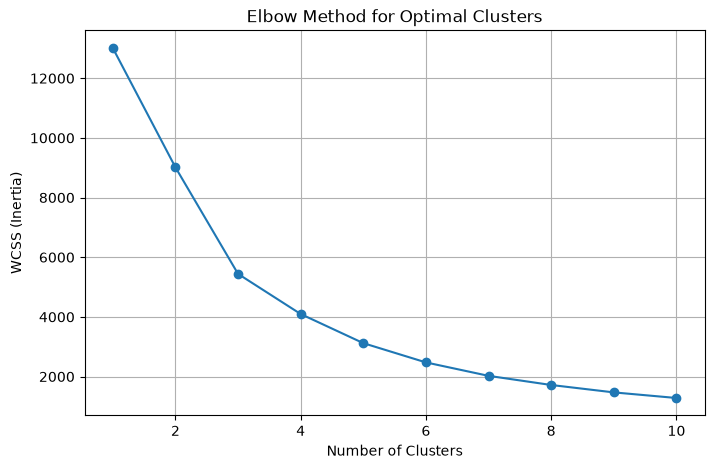

In [18]:
# Calculate WCSS for different numbers of clusters
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

In [19]:
# Apply K-Means with 5 clusters
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

# Fit the model and assign cluster labels
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Display customer data with cluster labels
rfm.head()
rfm['Cluster'].value_counts().sort_index()

Cluster
0    3048
1    1063
2       8
3     213
4       6
Name: count, dtype: int64

Customer Segmentation – Recency vs Frequency

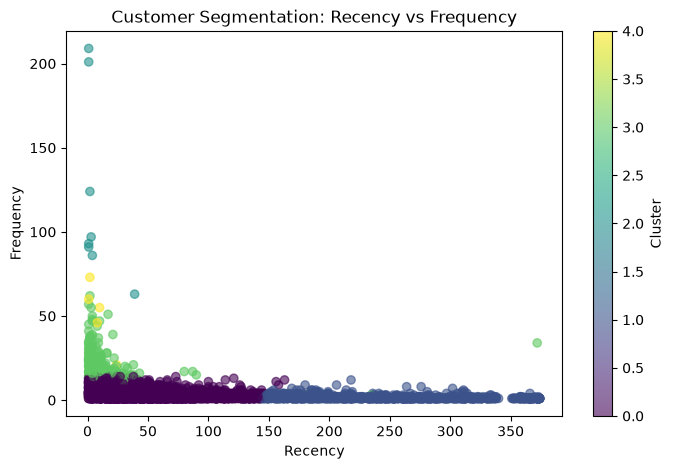

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(
    rfm['Recency'],
    rfm['Frequency'],
    c=rfm['Cluster'],
    cmap = 'viridis',
    alpha = 0.6
)

plt.title('Customer Segmentation: Recency vs Frequency')
plt.xlabel('Recency')
plt.ylabel('Frequency')
plt.colorbar(label='Cluster')
plt.show()

Customer Segmentation – Frequency vs Monetary

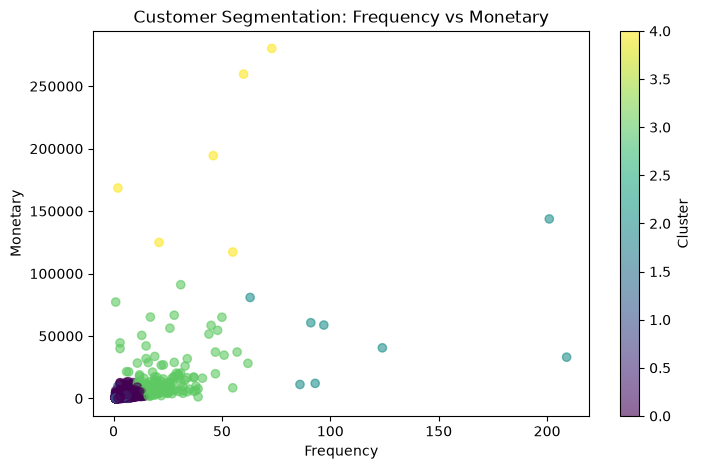

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    rfm['Frequency'],
    rfm['Monetary'],
    c=rfm['Cluster'],
    cmap='viridis',
    alpha=0.6
)

plt.title('Customer Segmentation: Frequency vs Monetary')
plt.xlabel('Frequency')
plt.ylabel('Monetary')
plt.colorbar(label='Cluster')
plt.show()

In [32]:
# Calculate average RFM values for each cluster
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Cluster': 'count'
}).rename(columns={'Cluster': 'Customer_Count'})

# Display cluster summary
cluster_summary.round(2)

,Recency,Frequency,Monetary,Customer_Count
Cluster,,,,
0,43.92,3.65,1333.13,3048
1,248.47,1.55,478.65,1063
2,6.50,120.50,55099.49,8
3,15.67,21.29,12813.94,213
4,7.67,42.83,190808.54,6


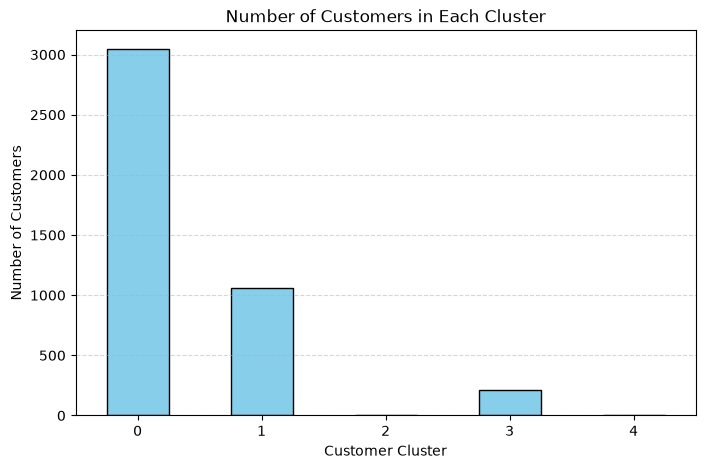

In [21]:
# Count customers in each cluster
cluster_counts = rfm['Cluster'].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(8, 5))

cluster_counts.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

## 13. Marketing Strategies and Business Recommendations

Based on the RFM analysis and K-Means clustering, customers were divided into five different segments. Each segment requires a different marketing strategy to improve customer engagement, satisfaction, and business revenue.

### Recommended Marketing Strategies

| Cluster | Customer Segment | Marketing Strategy |
|---|---|---|
| 0 | Regular Customers | Offer loyalty points, discounts, and personalised product recommendations to encourage repeat purchases. |
| 1 | Inactive Customers | Send re-engagement emails, special discount coupons, and attractive comeback offers to encourage customers to purchase again. |
| 2 | Very High-Value Customers | Provide exclusive benefits, premium offers, and personalised services to maintain their loyalty. |
| 3 | Loyal Customers | Introduce VIP rewards, membership benefits, referral programs, and special discounts. |
| 4 | Premium VIP Customers | Offer personalised promotions, priority customer support, exclusive experiences, and premium membership benefits. |

### Business Recommendations

1. **Customer Retention:** Focus on retaining high-value and loyal customers through rewards and personalised services.
2. **Customer Re-engagement:** Target inactive customers with special offers and promotional campaigns.
3. **Loyalty Programs:** Introduce reward points and membership benefits to increase purchase frequency.
4. **Personalised Marketing:** Recommend products based on individual customer purchasing behaviour.
5. **Revenue Growth:** Focus on high-value customer segments to maximise business revenue.
6. **Regular Monitoring:** Perform RFM analysis periodically to track changes in customer purchasing behaviour.

### Conclusion

Customer segmentation using RFM analysis and K-Means clustering helps businesses understand different types of customers based on their purchasing behaviour. By identifying regular, inactive, loyal, and high-value customers, businesses can develop targeted marketing strategies, improve customer retention, increase customer satisfaction, and maximise overall revenue.